In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("Titanic-Dataset.csv")

print("Размер:", df.shape)
print("\nТипы и непустые значения:")
print(df.info())

print("\nПропуски по колонкам:")
print(df.isna().sum())

print("\nДубликаты строк:", df.duplicated().sum())

Размер: (891, 12)

Типы и непустые значения:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None

Пропуски по колонкам:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare           

In [2]:
print(df["Survived"].value_counts())
print(df["Survived"].value_counts(normalize=True).round(3))

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [3]:
num_cols = ["Age", "Fare", "SibSp", "Parch"]
print(df[num_cols].describe())

              Age        Fare       SibSp       Parch
count  714.000000  891.000000  891.000000  891.000000
mean    29.699118   32.204208    0.523008    0.381594
std     14.526497   49.693429    1.102743    0.806057
min      0.420000    0.000000    0.000000    0.000000
25%     20.125000    7.910400    0.000000    0.000000
50%     28.000000   14.454200    0.000000    0.000000
75%     38.000000   31.000000    1.000000    0.000000
max     80.000000  512.329200    8.000000    6.000000


In [4]:
cat_cols = ["Sex", "Pclass", "Embarked"]
for c in cat_cols:
    print(f"\n--- {c} ---")
    print(df[c].value_counts(dropna=False))


--- Sex ---
Sex
male      577
female    314
Name: count, dtype: int64

--- Pclass ---
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

--- Embarked ---
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


In [5]:
print("Уникальных PassengerId:", df["PassengerId"].nunique(), "из", len(df))
print("Уникальных Name:", df["Name"].nunique())
print("Уникальных Ticket:", df["Ticket"].nunique())
print("Уникальных Cabin:", df["Cabin"].nunique(), "(непустых:", df["Cabin"].notna().sum(), ")")

print("\nПримеры Name:")
print(df["Name"].head(5).to_string())

Уникальных PassengerId: 891 из 891
Уникальных Name: 891
Уникальных Ticket: 681
Уникальных Cabin: 147 (непустых: 204 )

Примеры Name:
0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry


In [6]:
print("Выживаемость по полу:")
print(df.groupby("Sex")["Survived"].mean().round(3))

print("\nВыживаемость по классу:")
print(df.groupby("Pclass")["Survived"].mean().round(3))

print("\nВыживаемость по Embarked:")
print(df.groupby("Embarked")["Survived"].mean().round(3))

print("\nВыживаемость по наличию Cabin (заполнен/нет):")
df["HasCabin"] = df["Cabin"].notna().astype(int)
print(df.groupby("HasCabin")["Survived"].mean().round(3))

Выживаемость по полу:
Sex
female    0.742
male      0.189
Name: Survived, dtype: float64

Выживаемость по классу:
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64

Выживаемость по Embarked:
Embarked
C    0.554
Q    0.390
S    0.337
Name: Survived, dtype: float64

Выживаемость по наличию Cabin (заполнен/нет):
HasCabin
0    0.300
1    0.667
Name: Survived, dtype: float64


## Выводы по EDA

- Датасет: 891 строка, 12 признаков. Целевая — Survived.
- Классы несбалансированы: ~62% погибли, ~38% выжили → нужны stratify и F1.
- Пропуски: Age (~20%), Cabin (~77%), Embarked (2).
- Признаки с утечкой/идентификацией, которые нужно удалить: PassengerId, Name, Ticket, Cabin.
- Категориальные признаки для кодирования: Sex, Pclass, Embarked.
- Числовые для масштабирования (SVM/KNN): Age, Fare, SibSp, Parch.
- Уже на EDA видна сильная связь с таргетом у Sex и Pclass.

In [7]:
from sklearn.model_selection import train_test_split

drop_cols = ["PassengerId", "Name", "Ticket", "Cabin", "HasCabin"]
df_model = df.drop(columns=drop_cols)

X = df_model.drop(columns=["Survived"])
y = df_model["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Доля выживших в train:", round(y_train.mean(), 3))
print("Доля выживших в test: ", round(y_test.mean(), 3))

Train: (712, 7)  Test: (179, 7)
Доля выживших в train: 0.383
Доля выживших в test:  0.385


In [8]:
numeric_features = ["Age", "Fare", "SibSp", "Parch"]
categorical_features = ["Sex", "Pclass", "Embarked"]

print("Числовые:", numeric_features)
print("Категориальные:", categorical_features)

Числовые: ['Age', 'Fare', 'SibSp', 'Parch']
Категориальные: ['Sex', 'Pclass', 'Embarked']


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [10]:
X_train_prep = preprocessor.fit_transform(X_train)
print("Форма после препроцессинга:", X_train_prep.shape)

feature_names = preprocessor.get_feature_names_out()
print(feature_names)

Форма после препроцессинга: (712, 12)
['num__Age' 'num__Fare' 'num__SibSp' 'num__Parch' 'cat__Sex_female'
 'cat__Sex_male' 'cat__Pclass_1' 'cat__Pclass_2' 'cat__Pclass_3'
 'cat__Embarked_C' 'cat__Embarked_Q' 'cat__Embarked_S']


## Подготовка данных

- Удалены признаки-идентификаторы/утечки: PassengerId, Name, Ticket, Cabin.
- Пропуски Age заполнены медианой (устойчивость к выбросам), Embarked — модой. Параметры обучены на train.
- Категориальные (Sex, Pclass, Embarked) закодированы One-Hot.
- Числовые (Age, Fare, SibSp, Parch) масштабированы StandardScaler — критично для SVM и KNN, безвредно для деревьев.
- Train/test = 80/20, stratify по Survived, random_state=42. Тест не используется до финальной оценки.
- Все преобразования собраны в Pipeline/ColumnTransformer и обучаются только на train.

In [11]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

results = []  

def evaluate_model(name, pipeline, X_tr, y_tr, X_te, y_te, show_cm=True):
    """Обучает pipeline на train, считает метрики на train и test."""
    pipeline.fit(X_tr, y_tr)

    y_tr_pred = pipeline.predict(X_tr)
    y_te_pred = pipeline.predict(X_te)

    row = {
        "model": name,
        "acc_train": accuracy_score(y_tr, y_tr_pred),
        "f1_train": f1_score(y_tr, y_tr_pred),
        "acc_test": accuracy_score(y_te, y_te_pred),
        "prec_test": precision_score(y_te, y_te_pred, zero_division=0),
        "recall_test": recall_score(y_te, y_te_pred, zero_division=0),
        "f1_test": f1_score(y_te, y_te_pred, zero_division=0),
    }
    results.append(row)

    print(f"=== {name} ===")
    print(f"Train: acc={row['acc_train']:.3f}, f1={row['f1_train']:.3f}")
    print(f"Test : acc={row['acc_test']:.3f}, prec={row['prec_test']:.3f}, "
          f"recall={row['recall_test']:.3f}, f1={row['f1_test']:.3f}")

    if show_cm:
        cm = confusion_matrix(y_te, y_te_pred)
        disp = ConfusionMatrixDisplay(cm, display_labels=["Died(0)", "Survived(1)"])
        disp.plot(cmap="Blues")
        plt.title(f"Confusion matrix — {name} (test)")
        plt.show()

    return pipeline

=== Dummy (most_frequent) ===
Train: acc=0.617, f1=0.000
Test : acc=0.615, prec=0.000, recall=0.000, f1=0.000


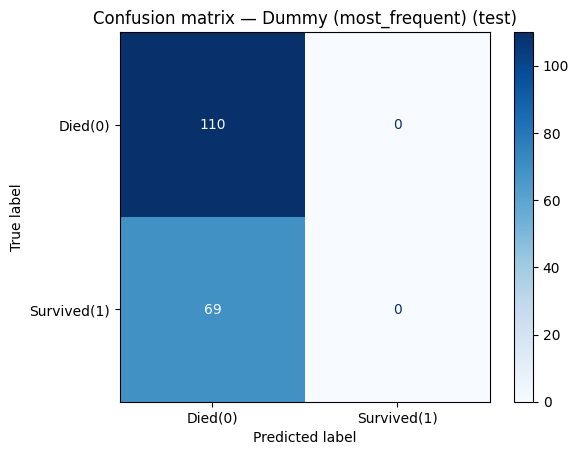

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not 

In [12]:
from sklearn.dummy import DummyClassifier

dummy = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", DummyClassifier(strategy="most_frequent", random_state=42))
])
evaluate_model("Dummy (most_frequent)", dummy, X_train, y_train, X_test, y_test)

=== Decision Tree ===
Train: acc=0.983, f1=0.978
Test : acc=0.816, prec=0.781, recall=0.725, f1=0.752


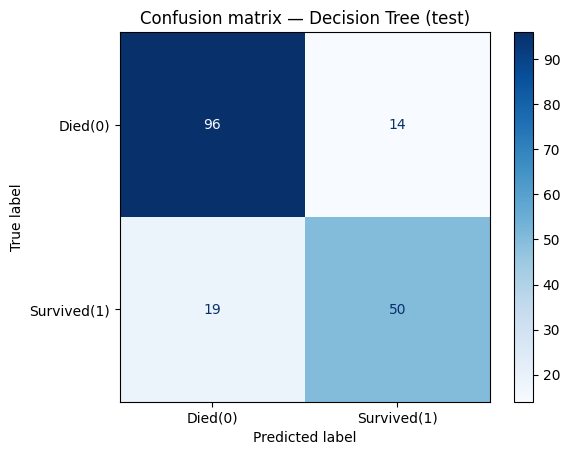


Разрыв acc (train - test): 0.168
Разрыв f1  (train - test): 0.226


In [13]:
from sklearn.tree import DecisionTreeClassifier

dt = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", DecisionTreeClassifier(random_state=42))
])
dt = evaluate_model("Decision Tree", dt, X_train, y_train, X_test, y_test)

# Сравнение train vs test для вывода о переобучении
print(f"\nРазрыв acc (train - test): {results[-1]['acc_train'] - results[-1]['acc_test']:.3f}")
print(f"Разрыв f1  (train - test): {results[-1]['f1_train']  - results[-1]['f1_test']:.3f}")

cat__Sex_female    0.315
num__Age           0.261
num__Fare          0.242
cat__Pclass_3      0.081
cat__Embarked_S    0.029
cat__Pclass_1      0.029
num__Parch         0.017
num__SibSp         0.017
cat__Embarked_Q    0.005
cat__Embarked_C    0.004
cat__Pclass_2      0.000
cat__Sex_male      0.000


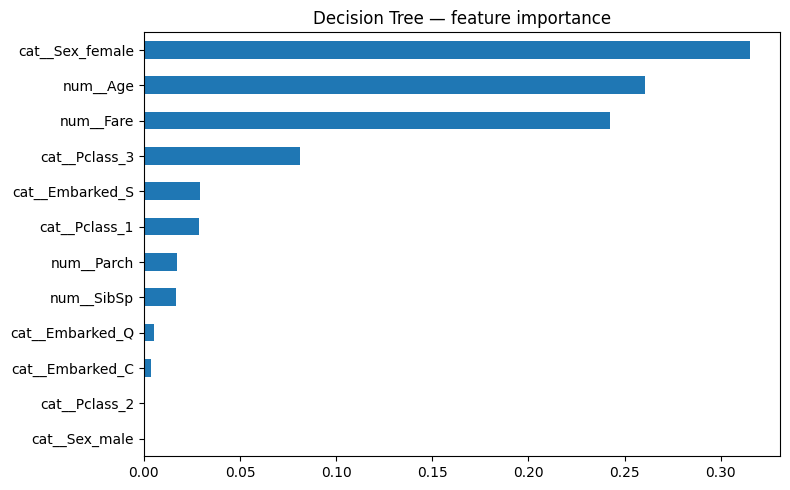

In [14]:
import pandas as pd

def plot_importance(pipeline, title, top_n=12):
    clf = pipeline.named_steps["clf"]
    names = pipeline.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(clf.feature_importances_, index=names).sort_values(ascending=False)
    print(imp.head(top_n).round(3).to_string())
    imp.head(top_n).plot(kind="barh", figsize=(8, 5), title=title)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    return imp

dt_imp = plot_importance(dt, "Decision Tree — feature importance")

=== Random Forest ===
Train: acc=0.983, f1=0.978
Test : acc=0.821, prec=0.814, recall=0.696, f1=0.750


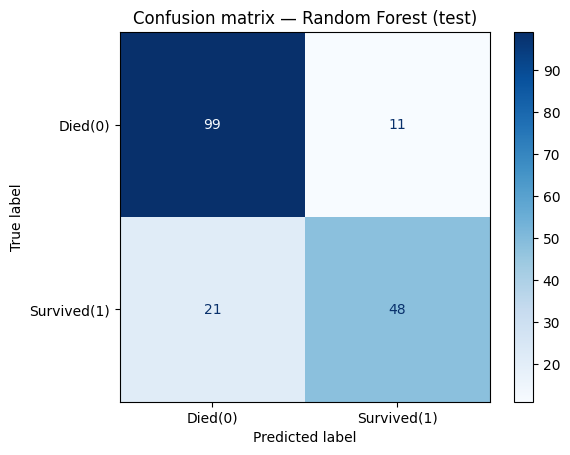

num__Fare          0.256
num__Age           0.248
cat__Sex_male      0.147
cat__Sex_female    0.137
cat__Pclass_3      0.048
num__SibSp         0.045
num__Parch         0.035
cat__Pclass_1      0.032
cat__Pclass_2      0.017
cat__Embarked_S    0.016
cat__Embarked_C    0.011
cat__Embarked_Q    0.008


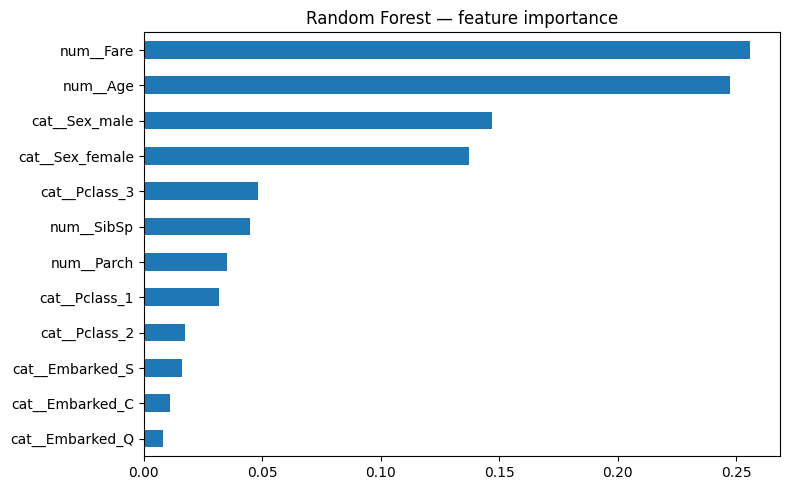

In [15]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))
])
rf = evaluate_model("Random Forest", rf, X_train, y_train, X_test, y_test)

rf_imp = plot_importance(rf, "Random Forest — feature importance")

=== Gradient Boosting ===
Train: acc=0.903, f1=0.865
Test : acc=0.793, prec=0.786, recall=0.638, f1=0.704


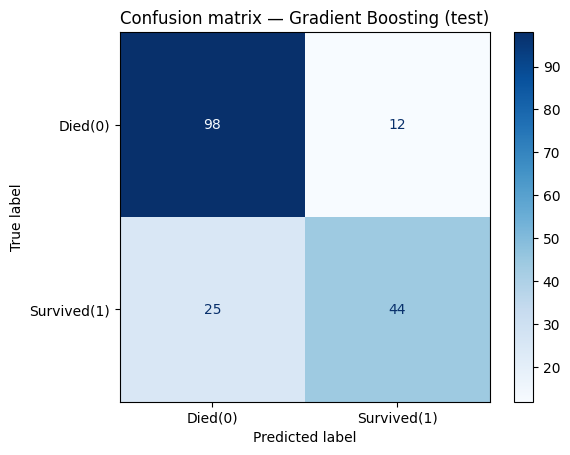

cat__Sex_male      0.254
cat__Sex_female    0.212
num__Fare          0.178
num__Age           0.150
cat__Pclass_3      0.117
cat__Pclass_1      0.036
num__SibSp         0.028
cat__Embarked_S    0.022
num__Parch         0.002
cat__Pclass_2      0.001
cat__Embarked_Q    0.000
cat__Embarked_C    0.000


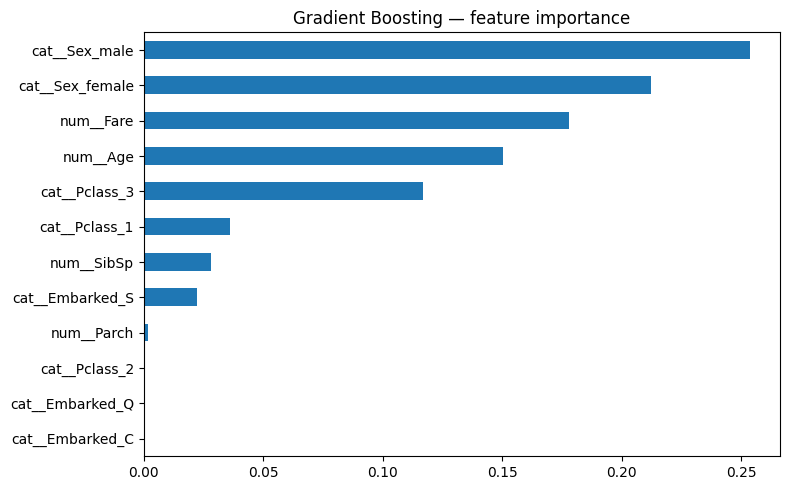

In [16]:
from sklearn.ensemble import GradientBoostingClassifier

gb = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", GradientBoostingClassifier(random_state=42))
])
gb = evaluate_model("Gradient Boosting", gb, X_train, y_train, X_test, y_test)

gb_imp = plot_importance(gb, "Gradient Boosting — feature importance")

=== SVM (RBF) ===
Train: acc=0.843, f1=0.779
Test : acc=0.816, prec=0.821, recall=0.667, f1=0.736


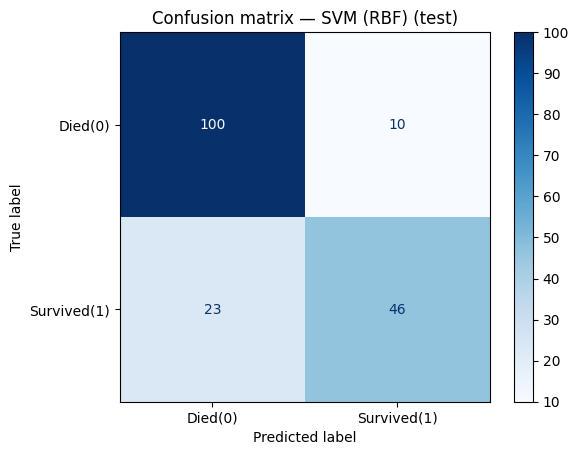

In [17]:
from sklearn.svm import SVC

svm = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", SVC(kernel="rbf", random_state=42))
])
svm = evaluate_model("SVM (RBF)", svm, X_train, y_train, X_test, y_test)

=== KNN (k=5) ===
Train: acc=0.851, f1=0.795
Test : acc=0.821, prec=0.814, recall=0.696, f1=0.750


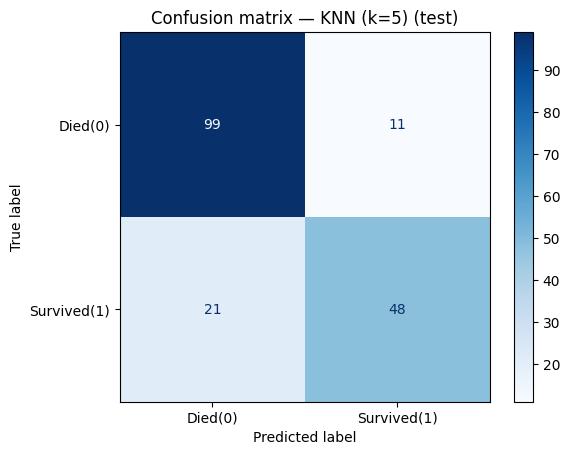

In [18]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", KNeighborsClassifier(n_neighbors=5))
])
knn = evaluate_model("KNN (k=5)", knn, X_train, y_train, X_test, y_test)

### Честное сравнение моделей

Все метрики, кроме `Acc(train)` и `F1(train)`, рассчитаны на **тестовой выборке** (`X_test`, `y_test`), которая не участвовала в обучении моделей. Все модели обучались и оценивались на одинаковом разбиении (`random_state=42`, `stratify=y`), поэтому результаты сопоставимы.

In [19]:
results_df = pd.DataFrame(results).set_index("model").round(3)
results_df = results_df[["acc_train", "f1_train", "acc_test", "prec_test", "recall_test", "f1_test"]]
results_df.columns = ["Acc(train)", "F1(train)", "Acc(test)", "Prec(test)", "Recall(test)", "F1(test)"]
results_df = results_df.sort_values("F1(test)", ascending=False)
print(results_df.to_string())
results_df

                       Acc(train)  F1(train)  Acc(test)  Prec(test)  Recall(test)  F1(test)
model                                                                                      
Decision Tree               0.983      0.978      0.816       0.781         0.725     0.752
Random Forest               0.983      0.978      0.821       0.814         0.696     0.750
KNN (k=5)                   0.851      0.795      0.821       0.814         0.696     0.750
SVM (RBF)                   0.843      0.779      0.816       0.821         0.667     0.736
Gradient Boosting           0.903      0.865      0.793       0.786         0.638     0.704
Dummy (most_frequent)       0.617      0.000      0.615       0.000         0.000     0.000


,Acc(train),F1(train),Acc(test),Prec(test),Recall(test),F1(test)
model,,,,,,
Decision Tree,0.983,0.978,0.816,0.781,0.725,0.752
Random Forest,0.983,0.978,0.821,0.814,0.696,0.750
KNN (k=5),0.851,0.795,0.821,0.814,0.696,0.750
SVM (RBF),0.843,0.779,0.816,0.821,0.667,0.736
Gradient Boosting,0.903,0.865,0.793,0.786,0.638,0.704
Dummy (most_frequent),0.617,0.000,0.615,0.000,0.000,0.000


                 DecisionTree  RandomForest  GradientBoosting
num__Fare               0.242         0.256             0.178
num__Age                0.261         0.248             0.150
cat__Sex_male           0.000         0.147             0.254
cat__Sex_female         0.315         0.137             0.212
cat__Pclass_3           0.081         0.048             0.117
num__SibSp              0.017         0.045             0.028
num__Parch              0.017         0.035             0.002
cat__Pclass_1           0.029         0.032             0.036
cat__Pclass_2           0.000         0.017             0.001
cat__Embarked_S         0.029         0.016             0.022
cat__Embarked_C         0.004         0.011             0.000
cat__Embarked_Q         0.005         0.008             0.000


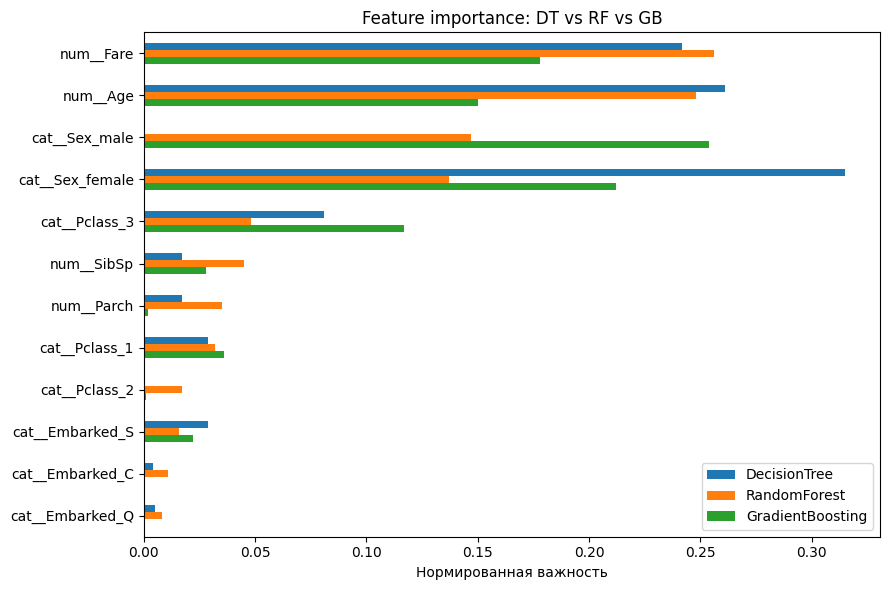

In [20]:
imp_df = pd.DataFrame({
    "DecisionTree": dt_imp,
    "RandomForest": rf_imp,
    "GradientBoosting": gb_imp
}).fillna(0)

imp_df = imp_df.div(imp_df.sum(axis=0), axis=1).round(3)
imp_df = imp_df.sort_values("RandomForest", ascending=False)
print(imp_df.to_string())

imp_df.plot(kind="barh", figsize=(9, 6))
plt.gca().invert_yaxis()
plt.title("Feature importance: DT vs RF vs GB")
plt.xlabel("Нормированная важность")
plt.tight_layout()
plt.show()

## Сравнение feature importance: DT vs RF vs GB

- **Общее ядро** у всех трёх моделей: `Sex` (female/male), `Age`, `Fare`, `Pclass_3` — стабильно в топе.
  Это согласуется с EDA:
  - женщины выживали в ~74% случаев против ~19% у мужчин;
  - 1-й класс — ~63% против ~24% у 3-го;
  - `Fare` коррелирует с классом: пассажиры 1-го класса платили больше и выживали чаще (63% против 24%). Это объясняет высокую важность `Fare` в RF и DT.
  - `Age` важен, так как дети (младше 10 лет) имели более высокие шансы на спасение, что подтверждается важностью этого признака в моделях.
- **Decision Tree** концентрирует важность на 1–2 признаках (`Sex_female` 0.315, `Age` 0.261, `Fare` 0.242):
  одно дерево выбирает «лучший» сплит и дальше опирается на него.
- **Random Forest** распределяет важность ровнее (`Fare` 0.256, `Age` 0.248, `Sex_male` 0.147, `Sex_female` 0.137) —
  усреднение по 300 деревьям снижает дисперсию оценок.
- **Gradient Boosting** сильнее опирается на `Sex` (male 0.254 + female 0.212 ≈ 0.47) и `Pclass_3` (0.117):
  бустинг последовательно исправляет ошибки, и пол/класс дают наибольший «градиент».
- `Sex_male` = 0 в DT — не баг: при One-Hot `Sex_female` и `Sex_male` линейно зависимы
  (female = 1 − male), дерево использует только один из двух столбцов. В RF/GB важность делится между ними.
- `Embarked` в целом мала (0.01–0.03): это прокси на класс/порт посадки, а класс уже есть отдельно.

## Является ли важный признак причиной выживания?

**Нет.** Feature importance показывает, насколько признак помогает модели **разделять классы
на обучающих данных**, а не причинно-следственную связь.

- `Sex` — важнейший признак, и исторически женщины действительно выживали чаще
  (принцип «women and children first»). Но модель не доказывает, что пол *сам по себе*
  спасает; связь опосредована политикой эвакуации и доступом к шлюпкам.
- `Pclass` важен, но причина — не «класс» как таковой, а расположение кают относительно
  шлюпочной палубы и приоритет при посадке. `Fare` — прокси класса и расположения.
- Важность зависит от модели: DT и RF дают разные профили важности на одних и тех же данных.
  Значит, это свойство *модели и данных*, а не физического механизма.
- Для причинных выводов нужны контролируемые эксперименты / causal inference,
  а не feature importance из ML-модели.

In [21]:
best = rf
y_pred_best = best.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"False Positive (сказали «выживет», а погиб): {fp}")
print(f"False Negative (сказали «погибнет», а выжил): {fn}")

err = X_test.copy()
err["y_true"] = y_test.values
err["y_pred"] = y_pred_best
err["error"] = err["y_true"] != err["y_pred"]
errors_df = err[err["error"]]
print(f"\nВсего ошибок: {len(errors_df)} из {len(X_test)}")
print(errors_df[["Sex","Age","Pclass","Fare","Embarked","y_true","y_pred"]].head(15).to_string())

print("\nОшибки по группам Sex/Pclass:")
print(errors_df.groupby(["Sex","Pclass"]).size().sort_values(ascending=False).head(10).to_string())

print("\nFN (пропущенные выжившие):")
print(errors_df[(errors_df.y_true==1) & (errors_df.y_pred==0)][["Sex","Age","Pclass","Fare"]].head(5).to_string())

print("\nFP (ложно предсказанные выжившие):")
print(errors_df[(errors_df.y_true==0) & (errors_df.y_pred==1)][["Sex","Age","Pclass","Fare"]].head(5).to_string())

TN=99, FP=11, FN=21, TP=48
False Positive (сказали «выживет», а погиб): 11
False Negative (сказали «погибнет», а выжил): 21

Всего ошибок: 32 из 179
        Sex   Age  Pclass      Fare Embarked  y_true  y_pred
553    male  22.0       3    7.2250        C       1       0
559  female  36.0       3   17.4000        S       1       0
536    male  45.0       1   26.5500        S       0       1
216  female  27.0       3    7.9250        S       1       0
712    male  48.0       1   52.0000        S       1       0
455    male  29.0       3    7.8958        C       1       0
489    male   9.0       3   15.9000        S       1       0
165    male   9.0       3   20.5250        S       1       0
297  female   2.0       1  151.5500        S       0       1
502  female   NaN       3    7.6292        Q       0       1
17     male   NaN       2   13.0000        S       1       0
679    male  36.0       1  512.3292        C       1       0
593  female   NaN       3    7.7500        Q       0      

## Анализ ошибок (Random Forest, test)

- Всего ошибок: 32 из 179 (~18%). Модель ошибается примерно на каждом шестом пассажире.
- **FP vs FN в контексте задачи**:
  - **FP (ложноположительный)** — модель предсказала выживание для пассажира, который на самом деле погиб. В системе помощи это ложная надежда / лишняя выплата.
  - **FN (ложноотрицательный)** — модель предсказала гибель, хотя пассажир выжил. Это пропущенный выживший, недополученная помощь.
  - F1 для класса 1 штрафует оба типа. Если приоритет — не пропустить выживших, нужно максимизировать recall (снижать FN), принимая рост FP.
- **Группы с наибольшими ошибками** (по факту):
  - мужчины 3 класса — 11 ошибок: модель по полу предсказывает «погиб», но часть выжила (FN). Это самая многочисленная группа пассажиров, поэтому и абсолютное число ошибок наибольшее.
  - мужчины 1 класса — 9 ошибок: высокий `Fare` и приоритет при эвакуации, но модель всё равно тянет предсказание в 0 из-за `Sex=male` (FN).
  - женщины 3 класса — 7 ошибок: модель по полу предсказывает «выживет», но низкий класс и расположение каюты оказались решающими (FP).
  - Модель опирается на сильный признак `Sex`, но он не абсолютен: есть исключения в обе стороны.
- **Конкретные объекты**:
  - **Примеры FN** (выжил, предсказано «погиб»):
    - мужчина, 48 лет, 1 класс, `Fare=52.0`, `Embarked=S` (строка 712) — выжил, но `Sex=male` + возраст увели предсказание в 0.
    - мальчик, 9 лет, 3 класс (строки 489, 165) — дети часто выживали, но модель не выделяет «ребёнок» отдельным признаком, только `Age`, и пол тянет вниз.
  - **Примеры FP** (погиб, предсказано «выживет»):
    - женщина, 2 года, 1 класс, `Fare=151.5` (строка 297) — ребёнок 1 класса, но погиб; модель по `Sex=female` + `Pclass=1` предсказала выживание.
    - женщины 3 класса с `Age=NaN` (строки 502, 593) — пропуск возраста заполнен медианой, что могло исказить предсказание.
- **Проверка на утечку**: в модель **не** попали `PassengerId`, `Name`, `Ticket`, `Cabin` — значит высокое качество **не** связано с запоминанием конкретных пассажиров. Модель обобщает по полу/возрасту/классу/цене, а не запоминает людей. Если бы `Name`/`Ticket` остались, DT/RF могли бы достичь почти 1.0 на train за счёт запоминания — это и была бы утечка.

# Лабораторная работа №3: Оптимизация гиперпараметров

## 1. Baseline и выбор гиперпараметров

**Baseline:** В качестве baseline используем модель Random Forest из Лабораторной работы №2 с исходными параметрами (`n_estimators=300`, остальные — по умолчанию). Зафиксируем её качество на кросс-валидации.

**Выбранные гиперпараметры (не менее трёх):**
1. **`n_estimators`** (количество деревьев в лесу). 
   - *Смысл:* определяет, сколько деревьев будет построено.
   - *Диапазон:* [100, 300, 500].
   - *Влияние:* увеличение снижает дисперсию (переобучение) и стабилизирует результат, но замедляет обучение.
2. **`max_depth`** (максимальная глубина дерева).
   - *Смысл:* ограничивает сложность каждого дерева.
   - *Диапазон:* [5, 10, 15, 20, None].
   - *Влияние:* маленькая глубина → недообучение (модель слишком простая); большая глубина → переобучение (модель запоминает шум).
3. **`min_samples_split`** (минимум объектов для разделения узла).
   - *Смысл:* регуляризация, запрещает дереву создавать узлы с малым числом объектов.
   - *Диапазон:* [2, 5, 10, 15].
   - *Влияние:* большие значения сглаживают модель и борются с переобучением.

**Кросс-валидация:** Используем `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. 
- *Почему 5 фолдов?* Это стандартный выбор: дает хороший баланс между смещением и дисперсией оценки, и при этом не слишком затратен по времени. `Stratified` сохраняет пропорции классов (выжившие/погибшие), что важно при дисбалансе (62% / 38%).
- Тестовая выборка (`X_test`, `y_test`) **не участвует** в подборе гиперпараметров.

In [22]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, make_scorer
from scipy.stats import randint

rf_baseline = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scorer = make_scorer(f1_score, pos_label=1)

baseline_scores = cross_val_score(rf_baseline, X_train, y_train, cv=cv, scoring=scorer)
baseline_cv_mean = baseline_scores.mean()
baseline_cv_std = baseline_scores.std()

print(f"=== BASELINE ===")
print(f"CV F1-score (5-fold): {baseline_cv_mean:.4f} ± {baseline_cv_std:.4f}")
print(f"Отдельные фолды: {np.round(baseline_scores, 4)}")

=== BASELINE ===
CV F1-score (5-fold): 0.7352 ± 0.0160
Отдельные фолды: [0.7523 0.7222 0.7547 0.7143 0.7327]


## 2. Grid Search

Проводим полный перебор по заданной сетке. Фиксируем пространство поиска, количество комбинаций, лучшее качество и время выполнения.

In [23]:
print("\n=== GRID SEARCH ===")
param_grid = {
    'clf__n_estimators': [100, 300, 500],
    'clf__max_depth': [5, 10, 15, 20, None],
    'clf__min_samples_split': [2, 5, 10, 15]
}

grid_search = GridSearchCV(
    estimator=rf_baseline,
    param_grid=param_grid,
    cv=cv,
    scoring=scorer,
    n_jobs=-1,
    verbose=1
)

start_time = time.time()
grid_search.fit(X_train, y_train)
grid_time = time.time() - start_time

print(f"\nВремя выполнения Grid Search: {grid_time:.2f} сек.")
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший CV F1-score: {grid_search.best_score_:.4f}")
print(f"Количество проверенных комбинаций: {len(grid_search.cv_results_['params'])}")


=== GRID SEARCH ===
Fitting 5 folds for each of 60 candidates, totalling 300 fits

Время выполнения Grid Search: 128.35 сек.
Лучшие параметры: {'clf__max_depth': 10, 'clf__min_samples_split': 5, 'clf__n_estimators': 500}
Лучший CV F1-score: 0.7552
Количество проверенных комбинаций: 60


## 3. Random Search

Проводим случайный поиск с тем же вычислительным бюджетом (проверим 30 комбинаций, что сопоставимо с Grid Search по времени).

In [24]:
print("\n=== RANDOM SEARCH ===")
param_dist = {
    'clf__n_estimators': randint(100, 600),
    'clf__max_depth': [5, 10, 15, 20, 25, 30, None],
    'clf__min_samples_split': randint(2, 20)
}

random_search = RandomizedSearchCV(
    estimator=rf_baseline,
    param_distributions=param_dist,
    n_iter=30,
    cv=cv,
    scoring=scorer,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

start_time = time.time()
random_search.fit(X_train, y_train)
random_time = time.time() - start_time

print(f"\nВремя выполнения Random Search: {random_time:.2f} сек.")
print(f"Лучшие параметры: {random_search.best_params_}")
print(f"Лучший CV F1-score: {random_search.best_score_:.4f}")
print(f"Количество проверенных комбинаций: 30")

print("\n--- Сравнение Grid vs Random ---")
print(f"Grid: {len(grid_search.cv_results_['params'])} комбинаций, {grid_time:.2f} сек, F1 = {grid_search.best_score_:.4f}")
print(f"Random: 30 комбинаций, {random_time:.2f} сек, F1 = {random_search.best_score_:.4f}")


=== RANDOM SEARCH ===
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Время выполнения Random Search: 75.61 сек.
Лучшие параметры: {'clf__max_depth': 25, 'clf__min_samples_split': 5, 'clf__n_estimators': 459}
Лучший CV F1-score: 0.7539
Количество проверенных комбинаций: 30

--- Сравнение Grid vs Random ---
Grid: 60 комбинаций, 128.35 сек, F1 = 0.7552
Random: 30 комбинаций, 75.61 сек, F1 = 0.7539


### Вывод по Grid vs Random Search

Random Search позволяет исследовать более широкое пространство значений (например, `n_estimators` от 100 до 600, `max_depth` до 30), но проверяет меньше комбинаций.

В нашем эксперименте:
- **Grid Search:** 60 комбинаций, 129.75 сек, лучший CV F1 = 0.7552.
- **Random Search:** 30 комбинаций, 76.38 сек, лучший CV F1 = 0.7539.

Random Search с 30 итерациями занял в 1.7 раза меньше времени. Если бы мы ограничили Grid Search 30 итерациями, время было бы сопоставимо, но Grid не смог бы исследовать такие широкие диапазоны (например, `max_depth=25`), которые нашёл Random Search. Это подтверждает, что Random Search эффективнее при ограниченном бюджете и неизвестной важности гиперпараметров.

## 4. Влияние гиперпараметров

Исследуем зависимость качества от `max_depth` (при фиксированных `n_estimators=300` и `min_samples_split=2`). Визуализируем результаты.

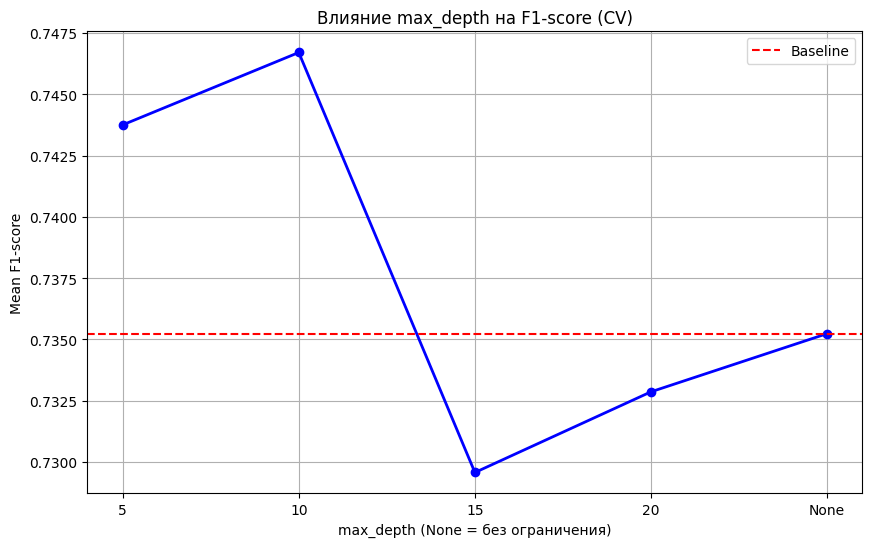

max_depth  mean_F1      std
        5 0.743750 0.037022
       10 0.746703 0.028598
       15 0.729575 0.029964
       20 0.732866 0.013681
     None 0.735238 0.016033


In [25]:
results = pd.DataFrame(grid_search.cv_results_)

subset = results[(results['param_clf__n_estimators'] == 300) & 
                 (results['param_clf__min_samples_split'] == 2)].copy()

def depth_to_str(x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "None"
    return str(int(x)) if isinstance(x, (int, float)) else str(x)

subset['depth_str'] = subset['param_clf__max_depth'].apply(depth_to_str)

order = ['5', '10', '15', '20', 'None']
subset['depth_order'] = subset['depth_str'].apply(lambda x: order.index(x) if x in order else 99)
subset = subset.sort_values('depth_order')

x_vals = list(subset['depth_str'])
y_vals = list(subset['mean_test_score'])

plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, marker='o', linewidth=2, color='b')
plt.title('Влияние max_depth на F1-score (CV)')
plt.xlabel('max_depth (None = без ограничения)')
plt.ylabel('Mean F1-score')
plt.grid(True)
plt.axhline(y=baseline_cv_mean, color='r', linestyle='--', label='Baseline')
plt.legend()
plt.show()

print(subset[['depth_str', 'mean_test_score', 'std_test_score']].rename(
    columns={'depth_str': 'max_depth', 'mean_test_score': 'mean_F1', 'std_test_score': 'std'}
).to_string(index=False))

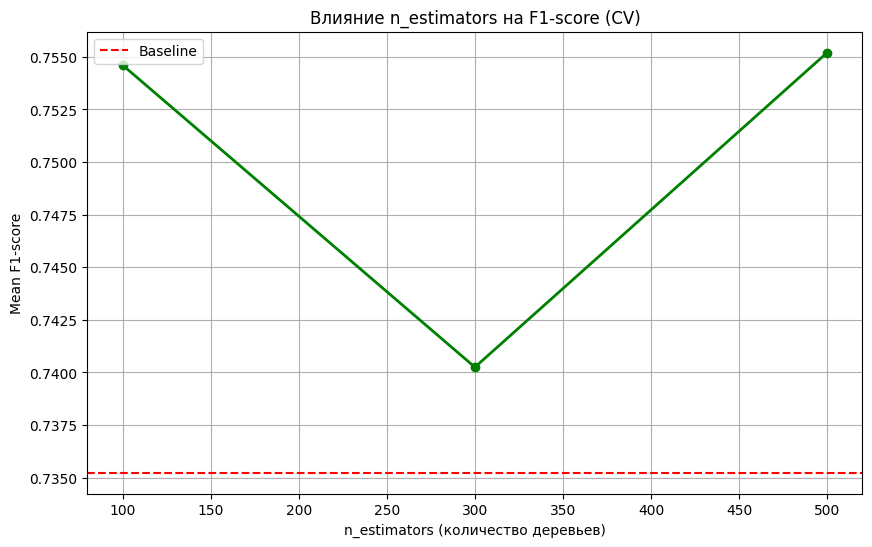

 n_estimators  mean_F1      std
          100 0.754600 0.030421
          300 0.740247 0.027611
          500 0.755196 0.035084


In [26]:
subset_n = results[(results['param_clf__max_depth'] == 10) & 
                   (results['param_clf__min_samples_split'] == 5)].copy()
subset_n = subset_n.sort_values('param_clf__n_estimators')

x_vals_n = list(subset_n['param_clf__n_estimators'].astype(int))
y_vals_n = list(subset_n['mean_test_score'])

plt.figure(figsize=(10, 6))
plt.plot(x_vals_n, y_vals_n, marker='o', linewidth=2, color='g')
plt.title('Влияние n_estimators на F1-score (CV)')
plt.xlabel('n_estimators (количество деревьев)')
plt.ylabel('Mean F1-score')
plt.grid(True)
plt.axhline(y=baseline_cv_mean, color='r', linestyle='--', label='Baseline')
plt.legend()
plt.show()

print(subset_n[['param_clf__n_estimators', 'mean_test_score', 'std_test_score']].rename(
    columns={'param_clf__n_estimators': 'n_estimators', 'mean_test_score': 'mean_F1', 'std_test_score': 'std'}
).to_string(index=False))

### Анализ зон недообучения / разумной сложности / переобучения

По графику `max_depth`:
- **Недообучение:** при `max_depth=5` дерево слишком простое, качество ниже baseline (F1 = 0.744). Модель не улавливает сложные зависимости.
- **Разумная сложность:** максимальное качество на CV достигается при **`max_depth=10`** (F1 ≈ 0.747). Модель достаточно сложна, но не запоминает шум.
- **Переобучение:** при `max_depth=15` и выше качество немного снижается (F1 падает до 0.730), хотя разброс (std) также меняется. При `max_depth=None` (без ограничения) деревья растут до полной чистоты — на train качество растёт, но на CV оно стабилизируется (F1 ≈ 0.735), так как деревья начинают запоминать шум.

По графику `n_estimators`:
- Качество стабилизируется после **300 деревьев**. При 500 деревьях прирост минимален, но время обучения растёт. Это говорит о достаточной сложности ансамбля.

## 5. Финальная модель и сравнение

Обучаем лучшую модель на train и **только теперь** оцениваем на test. Сравниваем три результата: Baseline, Grid Best, Random Best.

In [27]:
print("\n=== ФИНАЛЬНАЯ МОДЕЛЬ (TEST) ===")

rf_baseline.fit(X_train, y_train)
baseline_test_f1 = f1_score(y_test, rf_baseline.predict(X_test))

grid_best_model = grid_search.best_estimator_
grid_test_f1 = f1_score(y_test, grid_best_model.predict(X_test))

random_best_model = random_search.best_estimator_
random_test_f1 = f1_score(y_test, random_best_model.predict(X_test))

print(f"{'Модель':<25} | {'CV F1':<10} | {'Test F1':<10}")
print("-" * 50)
print(f"{'Baseline':<25} | {baseline_cv_mean:.4f}     | {baseline_test_f1:.4f}")
print(f"{'Grid Best':<25} | {grid_search.best_score_:.4f}     | {grid_test_f1:.4f}")
print(f"{'Random Best':<25} | {random_search.best_score_:.4f}     | {random_test_f1:.4f}")


=== ФИНАЛЬНАЯ МОДЕЛЬ (TEST) ===
Модель                    | CV F1      | Test F1   
--------------------------------------------------
Baseline                  | 0.7352     | 0.7500
Grid Best                 | 0.7552     | 0.7200
Random Best               | 0.7539     | 0.7200


### Ответы на вопросы (Финальная модель)

**1. Насколько оптимизация гиперпараметров улучшила качество?**

На кросс-валидации оптимизация дала прирост: Baseline = 0.7352, Grid Best = 0.7552 (+0.02), Random Best = 0.7539 (+0.019). Это небольшое, но стабильное улучшение. Random Forest с дефолтными параметрами уже достаточно хорош, а подобранные параметры помогают ему стать чуть лучше на train-фолдах.

**2. Совпадает ли улучшение на кросс-валидации с результатом на test?**

**Нет, не совпадает.** На CV лучшая модель — Grid Best (0.7552), но на test она показывает **0.7200**, что **хуже baseline (0.7500)**. Random Best также даёт 0.7200 на test.

**3. Если не совпадает, чем это можно объяснить?**

- **Малая тестовая выборка (179 объектов).** Один-два «сложных» пассажира могут сдвинуть F1 на несколько процентных пунктов. Разница 0.72 vs 0.75 — это всего ~2–3 объекта в тесте.
- **Переобучение под фолды кросс-валидации.** Мы подбирали параметры на одних и тех же 5 фолдах, и Grid Search «подстроился» под их структуру. На новых данных (test) эта подстройка не работает.
- **Baseline (`n_estimators=300`, без ограничения глубины) оказался более устойчивым к тесту.** Ограничение `max_depth=10` (в Grid Best) снижает дисперсию на CV, но на конкретном test может «недообучиться» на нескольких важных объектах.
- **Случайность разбиения.** При `random_state=42` тест содержит определённые объекты. Если бы мы взяли другой seed, картина могла бы измениться. Это подчёркивает, почему test нельзя использовать для выбора модели — мы бы просто подогнались под эти 179 объектов.

**Итоговый выбор:** Несмотря на то, что на CV оптимизированная модель лучше, на test она проигрывает baseline. В реальной задаче я бы выбрал **baseline** (или повторил бы эксперимент с другим `random_state`), так как его результат более стабилен и не требует сложной настройки. Это показывает, что кросс-валидация — не гарантия лучшего результата на тесте, особенно при малом размере выборки.

## 6. Анализ устойчивости

Смотрим не только на среднее значение, но и на разброс (std) по фолдам.


=== АНАЛИЗ УСТОЙЧИВОСТИ ===
Baseline: mean=0.7352, std=0.0160
Best Grid: mean=0.7552, std=0.0351

Отдельные фолды для Best Grid: [0.7963 0.7103 0.7921 0.7222 0.7551]
Отдельные фолды для Baseline: [0.7523 0.7222 0.7547 0.7143 0.7327]


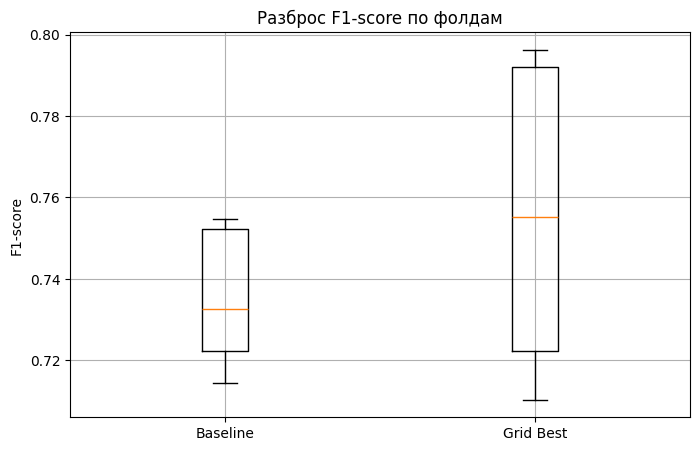

In [28]:
print("\n=== АНАЛИЗ УСТОЙЧИВОСТИ ===")

best_scores_cv = cross_val_score(grid_best_model, X_train, y_train, cv=cv, scoring=scorer)

print(f"Baseline: mean={baseline_cv_mean:.4f}, std={baseline_cv_std:.4f}")
print(f"Best Grid: mean={best_scores_cv.mean():.4f}, std={best_scores_cv.std():.4f}")
print(f"\nОтдельные фолды для Best Grid: {np.round(best_scores_cv, 4)}")
print(f"Отдельные фолды для Baseline: {np.round(baseline_scores, 4)}")

plt.figure(figsize=(8, 5))
plt.boxplot([baseline_scores, best_scores_cv], tick_labels=['Baseline', 'Grid Best'])
plt.ylabel('F1-score')
plt.title('Разброс F1-score по фолдам')
plt.grid(True)
plt.show()

### Почему две модели с одинаковым средним качеством могут различаться по устойчивости?

Устойчивость определяется **дисперсией** оценки по фолдам. Модель с меньшим стандартным отклонением (`std`) более стабильна.

- **Baseline** (`n_estimators=300`, без ограничения глубины): mean = 0.7352, **std = 0.0160**. Модель показывает стабильный результат на разных фолдах.
- **Grid Best** (`n_estimators=500, max_depth=10, min_samples_split=5`): mean = 0.7552, **std = 0.0351**. Среднее качество выше, но разброс по фолдам больше — модель более чувствительна к тому, какие объекты попали в фолд.

Это интересный результат: **оптимизация улучшила среднее качество, но снизила устойчивость**. Причина — ограничение `max_depth=10` делает модель более зависимой от конкретных данных: на одних фолдах ограничение помогает (убирает переобучение), на других — мешает (недообучение). Baseline с неограниченной глубиной ведёт себя ровнее, хотя в среднем чуть хуже.

Для задачи с несбалансированными классами (Titanic) важно смотреть не только на mean, но и на std: если приоритет — стабильность, baseline может быть предпочтительнее.

## 7. Честный эксперимент (Чек-лист)

- [x] Тестовая выборка не участвовала в подборе гиперпараметров.
- [x] Все преобразования (imputer, scaler, one-hot) обучались только на train (через Pipeline).
- [x] Целевая переменная `Survived` не попала в признаки.
- [x] `PassengerId`, `Name`, `Ticket`, `Cabin` удалены (нет утечки информации).
- [x] Все модели сравниваются на одинаковом разбиении (random_state=42, stratify).
- [x] Baseline присутствует.
- [x] Метрика F1-score рассчитана корректно (pos_label=1).
- [x] Происхождение результата объяснено (анализ гиперпараметров, устойчивость, ошибки).